# 04. GMM Theory and Training
**Goal:** Understand EM, fit the four GMM candidates, and select the model using training BIC.

**Input:** the scaled inputs from notebook 03.

**Output:** `models/gmm_models.joblib`, `results/gmm_selection.csv` and `results/model_settings.json`.

No validation or test label chooses the component count. This notebook can start in a fresh Python session.

### Files used in this notebook
- **Read from notebook 03:** `data/processed/features.npz`; use only its `X_train` array here.
- **Save for notebook 05:** `models/gmm_models.joblib` — the selected GMM and the K=1 reference.
- **Save as evidence:** `results/gmm_selection.csv`, `results/model_settings.json`, `figures/06_aic_bic.png`.

The model learns only from the legitimate training inputs. All fitting code is visible below.

## Setup for this notebook
Run from the project root or the `notebooks` folder. The next cell finds the root folder, so saved paths work in either case. Each notebook loads the previous stage's saved files. It does not depend on variables left in another notebook's Python session.

`Path` handles folders, `os.chdir` selects the project root, `pd` handles tables, `np` handles numbers, and `plt` draws charts. The `display` and `Image` tools show tables and pictures.

In [1]:
from pathlib import Path
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "requirements.txt").exists(), "Open this notebook from the project folder."
os.chdir(ROOT)
Path("figures").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

from sklearn.mixture import GaussianMixture
import joblib

**Files in the next cell:** `data/processed/features.npz`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

In [2]:
assert Path("data/processed/features.npz").exists(), "Run notebook 03 first."
arrays = np.load("data/processed/features.npz", allow_pickle=False)
X_train_scaled = arrays["X_train"]
print("GMM training input:", X_train_scaled.shape)

GMM training input: (169893, 29)


## 1. Understand the GMM before training it
A **Gaussian** is a bell-shaped pattern with a center and a spread. A **mixture** combines several such patterns. This lets the model describe legitimate data that has several centers.

**K** means the number of Gaussian components. Components are mathematical groups, not verified customer categories.

The GMM learns with a repeated process called **EM**:
1. **E-step:** estimate how much each transaction belongs to each component.
2. **M-step:** use those estimated memberships to update component centers, spreads, and weights.

Repeat until the estimates change very little.

### Our small set of choices
| Code setting | Plain meaning | Why we use it |
|---|---|---|
| `n_components=k` | Try k Gaussian components | Compare 1, 2, 4 and 8 |
| `covariance_type="diag"` | Learn each input's spread separately inside a component | A smaller, faster baseline |
| `n_init=3` | Try three starting arrangements | Reduce dependence on one starting arrangement |
| `max_iter=200` | Allow up to 200 EM rounds per start | Give fitting a clear limit |
| `reg_covar=1e-6` | Add a tiny amount to estimated variances | Avoid a spread collapsing to zero |
| `random_state=42` | Fix the starting randomness | Help reproduce the run |

A diagonal covariance is an approximation: real inputs can still have relationships that it misses.

![Teaching illustration of one Gaussian and a two-component mixture](../figures/gmm_teaching.png)

**Read the picture:** The left curve has one center. On the right, we add two weighted Gaussian curves to get the solid mixture curve. The illustration uses invented numbers only. Our real model uses 29 features and selects eight components. A two-feature picture cannot show all of those dimensions.

### See how bell curves form a mixture
This is a **teaching example with invented values**, not card data or a measured result. We draw one Gaussian centered at 0, then a mixture with centers at -2 and 2. `exp` and `sqrt` implement the Gaussian density formula. The mixture weights are 0.6 and 0.4 and add to 1. Our real model below has 29 inputs and tries four values of K.

**Save:** `figures/gmm_teaching.png`, used in `STUDY_GUIDE.md`.

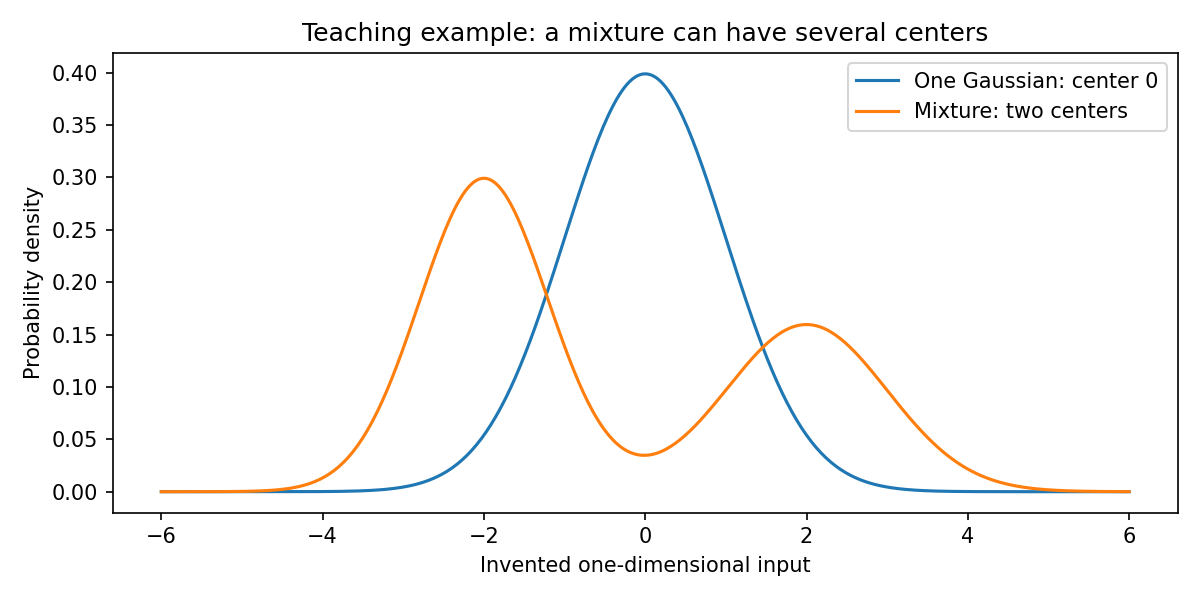

In [3]:
x = np.linspace(-6, 6, 400)
one_gaussian_curve = np.exp(-0.5 * x**2) / np.sqrt(2 * np.pi)
left_curve = np.exp(-0.5 * ((x + 2) / 0.8)**2) / (0.8 * np.sqrt(2 * np.pi))
right_curve = np.exp(-0.5 * (x - 2)**2) / np.sqrt(2 * np.pi)
mixture_curve = 0.6 * left_curve + 0.4 * right_curve

plt.figure(figsize=(8, 4))
plt.plot(x, one_gaussian_curve, label="One Gaussian: center 0")
plt.plot(x, mixture_curve, label="Mixture: two centers")
plt.xlabel("Invented one-dimensional input")
plt.ylabel("Probability density")
plt.title("Teaching example: a mixture can have several centers")
plt.legend()
plt.tight_layout()
plt.savefig("figures/gmm_teaching.png", dpi=150)
display(Image(filename="figures/gmm_teaching.png", width=800))
plt.close()

## 2. Fit four GMMs and choose K
**What we do:** Try K=1, 2, 4 and 8 on the same legitimate training inputs.

**How we choose:** AIC and BIC reward a better fit but penalize extra parameters. **Lower is better. We choose the smallest BIC.** We show AIC as an additional check; we do not switch between rules after seeing test results.

`fit` learns the model. `converged_` tells us whether the stopping rule was reached. The dictionaries store fitted models and their scores. The loop runs the same code once for each K.

**This cell:** Fit each candidate and display its training scores.

In [4]:
models = {}
selection_rows = []

for k in [1, 2, 4, 8]:
    gmm = GaussianMixture(n_components=k, covariance_type="diag", n_init=3,
                          max_iter=200, reg_covar=1e-6, random_state=42)
    gmm.fit(X_train_scaled)
    assert gmm.converged_, "This GMM did not finish fitting. Inspect it before continuing."
    models[k] = gmm
    selection_rows.append({"K": k, "AIC": gmm.aic(X_train_scaled), "BIC": gmm.bic(X_train_scaled),
                           "Converged": bool(gmm.converged_), "Iterations": int(gmm.n_iter_)})

selection = pd.DataFrame(selection_rows)
display(selection)

,K,AIC,BIC,Converged,Iterations
0,1,1.398204e+07,1.398263e+07,True,2
1,2,1.193484e+07,1.193601e+07,True,9
2,4,1.089440e+07,1.089676e+07,True,32
3,8,1.014018e+07,1.014492e+07,True,35


**This cell:** Choose the row with the smallest BIC, then retrieve that fitted model. No refitting happens here.

In [5]:
best_row = selection["BIC"].idxmin()
best_k = int(selection.loc[best_row, "K"])
model = models[best_k]
print("Chosen K:", best_k)

Chosen K: 8


**Code explanation:** `idxmin()` finds the row with the smallest BIC. `loc[best_row, "K"]` reads K from that row. `models[best_k]` retrieves the corresponding fitted model, so we do not fit it again.

**Result:** K=8 wins among our four choices. We do not claim eight is the best among every possible K. A lower BIC means better legitimate-data fit with its penalty; it does not guarantee better fraud detection.

**Files in the next cell:** `figures/06_aic_bic.png`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

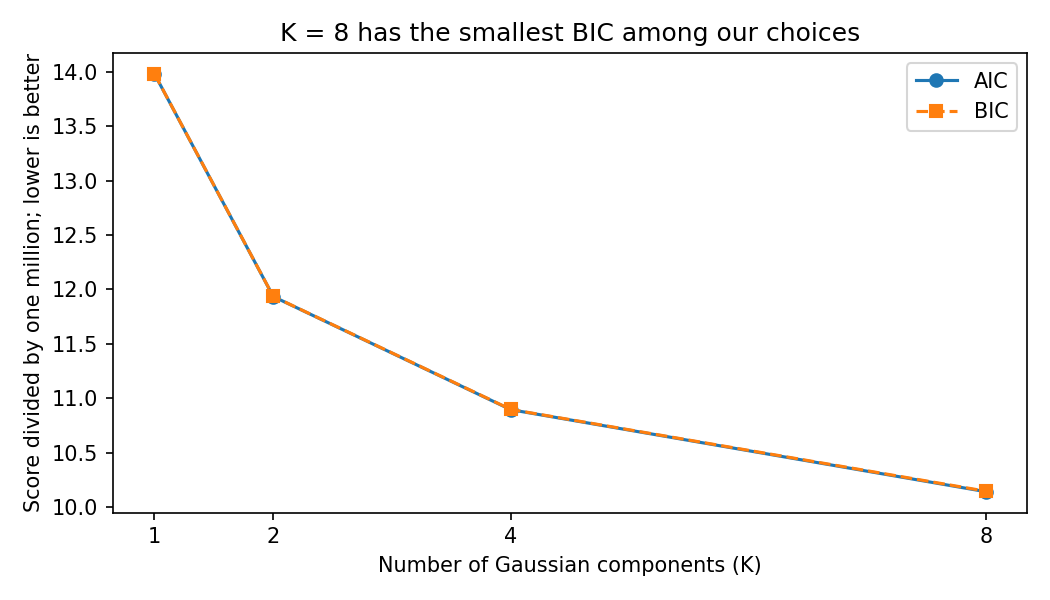

In [6]:
plt.figure(figsize=(7, 4))
plt.plot(selection["K"], selection["AIC"] / 1000000, "o-", label="AIC")
plt.plot(selection["K"], selection["BIC"] / 1000000, "s--", label="BIC")
plt.xticks([1, 2, 4, 8])
plt.xlabel("Number of Gaussian components (K)")
plt.ylabel("Score divided by one million; lower is better")
plt.title("K = 8 has the smallest BIC among our choices")
plt.legend()
plt.tight_layout()
plt.savefig("figures/06_aic_bic.png", dpi=150)
display(Image(filename="figures/06_aic_bic.png", width=800))
plt.close()

**Chart explanation:** The scores decrease as K increases in this small grid. The AIC and BIC lines are very close because their penalties differ by much less than the total fit score. Eight is also the largest K tried; the chart does not show that improvement has stopped.

## 3. A small theory reference
The GMM density is a weighted sum of Gaussian densities. The component weights add to one. EM tries to increase the total training log likelihood by alternating membership estimates and parameter updates.

For a transaction i and component k:

`membership(i,k) = weight(k) × Gaussian_k(x_i) / sum of [weight(j) × Gaussian_j(x_i)]`

The updated component center is an average of transaction values weighted by those memberships. This is why a transaction can partly influence more than one component. The report gives the mathematical notation; the study guide explains it in words.

`AIC = 2q - 2L` and `BIC = q × log(N) - 2L`.

N is the number of fitted rows, q is the number of adjustable parameters and L is total training log likelihood. For diagonal covariance with d inputs, `q = K(2d+1)-1`. At d=29 and K=8, this gives 471 parameters. You do not need to memorize 471; explain that more components require more learned numbers.

We also retain the K=1 candidate as a reference for evaluation. It already used the same legitimate training data and scaler, so comparing its PR curve with the selected GMM is straightforward.

## 4. Save the fitted models and settings
The selected GMM and the one-Gaussian reference are already fitted. Saving them does not refit them. `joblib.dump` stores the Python models locally for notebook 05.

Keep this input and model record so the results can be reproduced. Binary model files and large intermediate arrays are excluded from Git; the notebooks recreate them.

**Files in the next cell:** `models/gmm_models.joblib`, `results/gmm_selection.csv`, `results/model_settings.json`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

In [7]:
Path("models").mkdir(exist_ok=True)
joblib.dump({"selected_gmm": model, "one_gaussian": models[1]}, "models/gmm_models.joblib")
selection.to_csv("results/gmm_selection.csv", index=False)
settings = {"selected_K": best_k, "candidates": [1, 2, 4, 8],
    "selection_rule": "minimum training BIC among converged candidates",
    "covariance_type": "diag", "n_init": 3, "max_iter": 200,
    "reg_covar": 1e-6, "tol": 0.001, "random_state": 42,
    "training_rows": int(X_train_scaled.shape[0]), "inputs": int(X_train_scaled.shape[1])}
Path("results/model_settings.json").write_text(json.dumps(settings, indent=2))
print("Saved the fitted GMMs. Selected K:", best_k)

Saved the fitted GMMs. Selected K: 8


**Checkpoint:** All four candidates converged. K=8 has the smallest training BIC within our grid. It is also the largest tested value. This does not establish the best possible model or a guaranteed fraud score.

**Next:** `05_Evaluation_and_Thresholds.ipynb`.